# CASLEO follow-up × Rubin DP2: selección y curvas de luz

Este notebook no mide fuentes ni hace fotometría nueva. Presenta eventos previamente observados por CASLEO que tienen fotometría TOM disponible y productos catalogados en DP2. Lee las tablas publicadas `Source`, `ForcedSource`, `DiaSource` y `ForcedSourceOnDiaObject` vía TAP, y combina esos puntos con las curvas TOM existentes y un CSV opcional que se puede agregar al workspace.

Flujo: configurar → revisar candidatos (observados + fotometría + coincidencia DP2) → elegir `EVENT_NAMES` → leer las cuatro tablas ya medidas → graficar. TAP sólo consulta catálogos existentes; el cutout opcional sólo muestra el coadd.

In [1]:
from pathlib import Path
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from astropy.coordinates import SkyCoord
import astropy.units as u

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "target_selection" / "cache_paths.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Abrí el notebook desde este repositorio.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from target_selection.cache_paths import (
    OUTPUT_ROOT, CACHE_ROOT, MOP_PHOTOMETRY_CACHE, OGLE_PHOTOMETRY_CACHE,
    OPM_PHOTOMETRY_CACHE, BHTOM_PHOTOMETRY_CACHE,
)
from target_selection.data_release_config import get_data_release
from target_selection.target_registry import TargetRegistry
from target_selection.dia_catalog_cutouts import save_dia_match_cutout
from lsst.rsp import RSPDiscovery
from lsst.daf.butler import Butler

# Ajustar corrida/inventario si corresponde.
DATA_RELEASE = "DP2"
DATABASE_PATH = OUTPUT_ROOT / "target_database" / "target_selection.sqlite"
CSV_LOCATIONS = [Path.cwd() / "casleo_tom_photometry.csv",
                PROJECT_ROOT.parent / "casleo_tom_photometry.csv",
                PROJECT_ROOT / "casleo_tom_photometry.csv",
                PROJECT_ROOT / "data" / "casleo_tom_photometry.csv"]
EXTRA_TOM_PHOTOMETRY_CSV = next((path for path in CSV_LOCATIONS if path.exists()), CSV_LOCATIONS[0])
MATCH_RADIUS_ARCSEC = 1.0
OUTPUT_DIR = OUTPUT_ROOT / "runs" / "casleo_lsst_presentation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

release = get_data_release(DATA_RELEASE)
tap_service = RSPDiscovery(release.rsp_instance).get_tap_client()
butler = Butler(release.butler_repo, **({"collections": release.butler_collections} if release.butler_collections else {}))
registry = TargetRegistry(DATABASE_PATH)
print("CSV extra (opcional):", EXTRA_TOM_PHOTOMETRY_CSV)


CSV extra (opcional): /home/karennowo/target_selection/notebooks/casleo_tom_photometry.csv


## 1. Candidatos: observados, con fotometría TOM y presentes en DP2

La lista de observados viene del registro de seguimiento (`HSH`/`JS`). La fotometría TOM se reúne desde la fotometría guardada en el registro, los CSV cacheados de MOP/OGLE/OPM/BHTOM y el CSV externo opcional. Para agregar un archivo, guardalo como `casleo_tom_photometry.csv` en el directorio desde el que abrís Jupyter, en el workspace (`/home/karennowo`), en la raíz del proyecto o en `data/`. Se aceptan columnas `Target`, fecha (`mjd` o `Timestamp`), magnitud (`magnitude` o `Magnitude`), incertidumbre opcional (`magnitude_error` o `Error`) y filtro (`band` o `Filter`).

La tabla de abajo informa si el target tiene una coincidencia espacial en `Object` y/o `DiaObject`. Elegí manualmente los eventos en `EVENT_NAMES` en la siguiente sección.

In [2]:
def safe_name(value):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("._")

def normalize_tom(frame, provider="TOM"):
    if frame is None or frame.empty:
        return pd.DataFrame(columns=["Target", "mjd", "band", "magnitude", "magnitude_error", "provider", "survey"])
    data = frame.copy()
    aliases = {"target": "Target", "target_id": "Target", "MJD": "mjd", "Timestamp": "timestamp",
               "Magnitude": "magnitude", "Error": "magnitude_error", "magnitude_err": "magnitude_error", "Filter": "band",
               "Provider": "provider", "Survey": "survey", "Source": "survey",
               "source": "survey", "Telescope": "survey", "telescope": "survey",
               "Facility": "survey", "facility": "survey", "dataset_id": "survey"}
    for old, new in aliases.items():
        if new not in data and old in data:
            data = data.rename(columns={old: new})
    if "timestamp" not in data and "observation_time" in data:
        data["timestamp"] = data["observation_time"]
    if "timestamp" in data:
        timestamp = pd.to_datetime(data["timestamp"], errors="coerce", utc=True, format="mixed").dt.tz_convert(None)
        data["mjd"] = data.get("mjd", pd.Series(np.nan, index=data.index)).fillna(
            (timestamp - pd.Timestamp("1858-11-17")) / pd.Timedelta(days=1)
        )
    if "epoch_mjd" in data:
        data["mjd"] = data.get("mjd", pd.Series(np.nan, index=data.index)).fillna(pd.to_numeric(data["epoch_mjd"], errors="coerce"))
    if "epoch_hjd" in data:
        data["mjd"] = data.get("mjd", pd.Series(np.nan, index=data.index)).fillna(pd.to_numeric(data["epoch_hjd"], errors="coerce") - 2400000.5)
    if "Target" not in data or "mjd" not in data or "magnitude" not in data:
        return pd.DataFrame(columns=["Target", "mjd", "band", "magnitude", "magnitude_error", "provider", "survey"])
    for column, default in (("band", ""), ("magnitude_error", np.nan), ("provider", provider), ("survey", "")):
        if column not in data:
            data[column] = default
    data["provider"] = data["provider"].fillna(provider).astype(str).str.strip().str.upper()
    data["survey"] = data["survey"].fillna("").astype(str).str.strip()
    band_prefix = data["band"].astype(str).str.extract(r"^([A-Za-z]+)_", expand=False)
    data["survey"] = data["survey"].where(data["survey"].ne(""), band_prefix.fillna(""))
    data["survey"] = data["survey"].where(data["survey"].ne(""), data["provider"])
    data["band"] = data["band"].astype(str).str.replace(r"^(OGLE|ZTF|MOA|GAIA)_", "", regex=True)
    data["mjd"] = pd.to_numeric(data["mjd"], errors="coerce")
    data["magnitude"] = pd.to_numeric(data["magnitude"], errors="coerce")
    data["magnitude_error"] = pd.to_numeric(data["magnitude_error"], errors="coerce")
    return data.dropna(subset=["Target", "mjd", "magnitude"])[
        ["Target", "mjd", "band", "magnitude", "magnitude_error", "provider", "survey"]
    ]

# Datos guardados en target_selection (TOM/follow-up) más caches de surveys/TOMs.
observed = registry.observed_targets(providers=("HSH", "JS"))
if observed.empty:
    raise ValueError("El registro no contiene targets observados por HSH/JS.")
registry_points = registry.photometry(observed)
if not registry_points.empty and "provider" in registry_points:
    registry_points = registry_points.loc[
        registry_points["provider"].astype(str).str.casefold().isin({"mop", "bhtom", "opm"})
    ].copy()  # Excluye los puntos LSST/Rubin guardados como rubin_dp2.
tom_frames = [normalize_tom(registry_points, "registry")]
for provider, cache_dir in (("MOP", MOP_PHOTOMETRY_CACHE), ("OGLE", OGLE_PHOTOMETRY_CACHE),
                            ("OPM", OPM_PHOTOMETRY_CACHE), ("BHTOM", BHTOM_PHOTOMETRY_CACHE)):
    for target in observed["Target"].astype(str).unique():
        path = cache_dir / f"{safe_name(target)}.csv"
        if path.exists():
            try:
                cached = pd.read_csv(path)
                if "Target" not in cached and "target_id" not in cached:
                    cached["Target"] = target
                tom_frames.append(normalize_tom(cached, provider))
            except (OSError, ValueError) as exc:
                print(f"Se omite caché inválida {path.name}: {exc}")
if EXTRA_TOM_PHOTOMETRY_CSV.exists():
    tom_frames.append(normalize_tom(pd.read_csv(EXTRA_TOM_PHOTOMETRY_CSV), "CSV externo"))
tom_all = pd.concat([frame for frame in tom_frames if not frame.empty], ignore_index=True) if any(not f.empty for f in tom_frames) else pd.DataFrame(columns=["Target", "mjd", "band", "magnitude", "magnitude_error", "provider", "survey"])
if not tom_all.empty:
    tom_all = tom_all.loc[~tom_all["provider"].astype(str).str.casefold().isin({"rubin_dp2", "lsst", "rubin"})].copy()
if not tom_all.empty:
    tom_all["Target"] = tom_all["Target"].astype(str).str.strip()
    observed = observed.merge(tom_all.groupby("Target").size().rename("tom_points"), on="Target", how="inner")
else:
    observed["tom_points"] = 0
observed = observed.dropna(subset=["RA_deg", "Dec_deg"]).drop_duplicates("Target").reset_index(drop=True)
display(observed[[c for c in ["Target", "RA_deg", "Dec_deg", "observatory_providers", "tom_points"] if c in observed]])
print(f"Candidatos observados con fotometría TOM: {len(observed)}")


,Target,RA_deg,Dec_deg,observatory_providers,tom_points
0,ASASSN-24fs,296.495571,-7.924758,HSH,11411
1,Gaia24bsi,82.597058,-70.039561,"HSH,JS",402
2,Gaia24bsj,80.063592,-70.072961,"HSH,JS",139
3,Gaia24ddl,230.831108,-58.085411,HSH,243
4,OGLE-2023-BLG-0723,257.020625,-28.583972,HSH,131
5,OGLE-2023-GD-0011,244.605833,-54.078833,HSH,522
6,OGLE-2024-BLG-0002,276.250792,-21.028722,HSH,1107
7,OGLE-2024-BLG-0009,258.280583,-32.921556,HSH,338
8,OGLE-2024-BLG-0010,259.523083,-31.682806,HSH,318
9,OGLE-2024-BLG-0034,266.043333,-39.113222,HSH,3905


Candidatos observados con fotometría TOM: 28


## 2. Confirmar presencia en DP2 y elegir eventos

Se buscan coincidencias en los catálogos `Object` y `DiaObject` alrededor de la coordenada del target. La coincidencia más cercana se conserva junto con su separación; revisar la tabla, en especial en campos densos, antes de plotear. No se corre fotometría: son búsquedas de filas ya catalogadas.

In [3]:
def tap_frame(query):
    job = tap_service.submit_job(query)
    job.run()
    job.wait(phases=["COMPLETED", "ERROR"])
    if job.phase == "ERROR":
        job.raise_if_error()
    return job.fetch_result().to_table().to_pandas()

def nearest_catalog_match(table, ra_col, dec_col, ra, dec, radius_arcsec):
    radius_deg = radius_arcsec / 3600
    columns = "objectId, coord_ra, coord_dec" if table == "dp2.Object" else "diaObjectId, ra, dec"
    rows = tap_frame(f"""
        SELECT {columns} FROM {table}
        WHERE CONTAINS(POINT('ICRS', {ra_col}, {dec_col}),
                      CIRCLE('ICRS', {ra:.9f}, {dec:.9f}, {radius_deg:.9f})) = 1
    """)
    if rows.empty:
        return None
    target_coord = SkyCoord(ra * u.deg, dec * u.deg)
    catalog_coord = SkyCoord(pd.to_numeric(rows[ra_col], errors="coerce").to_numpy() * u.deg,
                             pd.to_numeric(rows[dec_col], errors="coerce").to_numpy() * u.deg)
    rows = rows.assign(separation_arcsec=target_coord.separation(catalog_coord).arcsec)
    return rows.sort_values("separation_arcsec").iloc[0]

candidate_rows = []
for target in observed.itertuples(index=False):
    obj = nearest_catalog_match("dp2.Object", "coord_ra", "coord_dec", target.RA_deg, target.Dec_deg, MATCH_RADIUS_ARCSEC)
    dia = nearest_catalog_match("dp2.DiaObject", "ra", "dec", target.RA_deg, target.Dec_deg, MATCH_RADIUS_ARCSEC)
    candidate_rows.append({
        "Target": target.Target, "RA_deg": target.RA_deg, "Dec_deg": target.Dec_deg,
        "observatory_providers": getattr(target, "observatory_providers", ""), "tom_points": int(target.tom_points),
        "objectId": int(obj.objectId) if obj is not None else pd.NA,
        "Object_sep_arcsec": float(obj.separation_arcsec) if obj is not None else np.nan,
        "diaObjectId": int(dia.diaObjectId) if dia is not None else pd.NA,
        "DiaObject_sep_arcsec": float(dia.separation_arcsec) if dia is not None else np.nan,
    })
candidates = pd.DataFrame(candidate_rows)
candidates["in_DP2"] = candidates["objectId"].notna() | candidates["diaObjectId"].notna()
display(candidates.loc[candidates["in_DP2"]].sort_values(["tom_points", "Target"], ascending=[False, True]))


,Target,RA_deg,Dec_deg,observatory_providers,tom_points,objectId,Object_sep_arcsec,diaObjectId,DiaObject_sep_arcsec,in_DP2
23,OGLE-2025-BLG-0715,261.177542,-21.279556,"HSH,JS",1263,<NA>,NaN,762348242544367360,0.206124,True
12,OGLE-2024-BLG-0669,275.089125,-18.269389,HSH,1251,<NA>,NaN,765564451494561280,0.163812,True
10,OGLE-2024-BLG-0592,275.976417,-26.652722,HSH,1146,<NA>,NaN,757795508491125888,0.135634,True
22,OGLE-2025-BLG-0681,278.391708,-13.703111,HSH,1112,<NA>,NaN,770402989851544832,0.237997,True
13,OGLE-2024-BLG-0674,262.735917,-21.828444,"HSH,JS",875,<NA>,NaN,762353052907735296,0.196413,True
15,OGLE-2024-GD-0001,251.794750,-39.899167,HSH,439,<NA>,NaN,744952319325510656,0.167678,True
17,OGLE-2024-GD-0014,251.849292,-40.118500,HSH,417,<NA>,NaN,744950944935968896,0.096447,True
18,OGLE-2025-BLG-0245,258.297833,-34.785389,HSH,401,<NA>,NaN,749016389179672320,0.160114,True
27,OGLE-2025-GD-0006,251.439167,-39.737750,HSH,365,<NA>,NaN,744953075239753216,0.657955,True
7,OGLE-2024-BLG-0009,258.280583,-32.921556,HSH,338,<NA>,NaN,750412631507996544,0.214556,True


In [4]:
# Eventos destacados en las diapositivas 18–19 de la presentación.
PREFERRED_EVENT_NAMES = [
    "OGLE-2025-BLG-0675",
    "OGLE-2024-BLG-0674",
    "OGLE-2025-GD-0001",
    "OGLE-2025-BLG-0397",
]
EXTRA_EVENT_NAMES = []  # Añadir aquí otros Target observados que quieras incluir.

ranked = candidates.loc[candidates["in_DP2"]].copy()
ranked["has_both_catalogs"] = ranked["objectId"].notna() & ranked["diaObjectId"].notna()
available_names = set(ranked["Target"].astype(str))
slide_events_found = [name for name in PREFERRED_EVENT_NAMES if name in available_names]
slide_events_missing = [name for name in PREFERRED_EVENT_NAMES if name not in available_names]
EVENT_NAMES = list(dict.fromkeys([*slide_events_found, *EXTRA_EVENT_NAMES]))

# Si alguna referencia de las diapositivas no tiene match DP2, completar hasta
# tres ejemplos con los candidatos que tienen más fotometría TOM.
if len(EVENT_NAMES) < 3:
    fill = ranked.loc[~ranked["Target"].astype(str).isin(EVENT_NAMES)].sort_values(
        ["has_both_catalogs", "tom_points"], ascending=[False, False], kind="stable"
    )["Target"].astype(str).tolist()
    EVENT_NAMES.extend(fill[:3 - len(EVENT_NAMES)])

if slide_events_missing:
    print("Sin coincidencia Object/DiaObject DP2 (se omiten):", ", ".join(slide_events_missing))
selected = candidates.loc[
    candidates["Target"].astype(str).isin(map(str, EVENT_NAMES)) & candidates["in_DP2"]
].copy()
selected = selected.merge(observed[["Target", "RA_deg", "Dec_deg"]], on="Target", suffixes=("", "_obs"))
selected["RA_deg"] = selected["RA_deg_obs"]
selected["Dec_deg"] = selected["Dec_deg_obs"]
print("Eventos elegidos:", ", ".join(selected["Target"].astype(str)))
display(selected)


Sin coincidencia Object/DiaObject DP2 (se omiten): OGLE-2025-BLG-0675, OGLE-2025-GD-0001, OGLE-2025-BLG-0397
Eventos elegidos: OGLE-2024-BLG-0669, OGLE-2024-BLG-0674, OGLE-2025-BLG-0715


,Target,RA_deg,Dec_deg,observatory_providers,tom_points,objectId,Object_sep_arcsec,diaObjectId,DiaObject_sep_arcsec,in_DP2,RA_deg_obs,Dec_deg_obs
0,OGLE-2024-BLG-0669,275.089125,-18.269389,HSH,1251,<NA>,NaN,765564451494561280,0.163812,True,275.089125,-18.269389
1,OGLE-2024-BLG-0674,262.735917,-21.828444,"HSH,JS",875,<NA>,NaN,762353052907735296,0.196413,True,262.735917,-21.828444
2,OGLE-2025-BLG-0715,261.177542,-21.279556,"HSH,JS",1263,<NA>,NaN,762348242544367360,0.206124,True,261.177542,-21.279556


## 3. Leer fotometría existente de los cuatro catálogos DP2

`Source` son detecciones en imágenes de visita; `ForcedSource` son mediciones forzadas en posiciones de `Object`; `DiaSource` contiene detecciones en imágenes diferencia; `ForcedSourceOnDiaObject` es fotometría forzada asociada a `DiaObject`. Se recuperan `psfFlux`/`psfFluxErr`, `psfDiffFlux`/`psfDiffFluxErr` cuando existen y el MJD. No se mide nada de nuevo.

Las búsquedas directas usan las coordenadas para `Source` y las IDs de objeto para las tablas forced. Las consultas quedan acotadas a los objetos elegidos y a una pequeña región del cielo.

In [5]:
def query_catalog_lightcurves(selected):
    rows = []
    for target in selected.itertuples(index=False):
        name, ra, dec = str(target.Target), float(target.RA_deg), float(target.Dec_deg)
        # Source: detecciones ya medidas cerca de la coordenada (sin asociar a Object).
        radius = MATCH_RADIUS_ARCSEC / 3600
        source = tap_frame(f"""
            SELECT s.visit, s.detector, s.band, s.ra, s.dec, s.psfFlux, s.psfFluxErr,
                   vd.expMidptMJD
            FROM dp2.Source AS s
            JOIN dp2.VisitDetector AS vd ON vd.visitId=s.visit AND vd.detector=s.detector
            WHERE CONTAINS(POINT('ICRS', s.ra, s.dec), CIRCLE('ICRS', {ra:.9f}, {dec:.9f}, {radius:.9f}))=1
        """)
        if not source.empty:
            coords = SkyCoord(pd.to_numeric(source.ra, errors="coerce").to_numpy()*u.deg,
                              pd.to_numeric(source.dec, errors="coerce").to_numpy()*u.deg)
            sep = SkyCoord(ra*u.deg, dec*u.deg).separation(coords).arcsec
            source = source.loc[sep <= MATCH_RADIUS_ARCSEC].copy()
            source["catalog"] = "Source"
            source["Target"] = name
            rows.append(source)

        object_id = target.objectId
        if pd.notna(object_id):
            forced = tap_frame(f"""
                SELECT fs.visit, fs.detector, fs.band, fs.psfFlux, fs.psfFluxErr, vd.expMidptMJD
                FROM dp2.ForcedSource AS fs
                JOIN dp2.VisitDetector AS vd ON vd.visitId=fs.visit AND vd.detector=fs.detector
                WHERE fs.objectId={int(object_id)}
            """)
            if not forced.empty:
                forced["catalog"] = "ForcedSource"; forced["Target"] = name; rows.append(forced)

        dia_id = target.diaObjectId
        if pd.notna(dia_id):
            dia = tap_frame(f"""
                SELECT ds.visit, ds.detector, ds.band, ds.psfFlux, ds.psfFluxErr, ds.isDipole, vd.expMidptMJD
                FROM dp2.DiaSource AS ds
                JOIN dp2.VisitDetector AS vd ON vd.visitId=ds.visit AND vd.detector=ds.detector
                WHERE ds.diaObjectId={int(dia_id)}
            """)
            if not dia.empty:
                dia["catalog"] = "DiaSource"; dia["Target"] = name; rows.append(dia)
            dia_forced = tap_frame(f"""
                SELECT fs.visit, fs.detector, fs.band, fs.psfFlux, fs.psfFluxErr,
                       fs.psfDiffFlux, fs.psfDiffFluxErr, vd.expMidptMJD
                FROM dp2.ForcedSourceOnDiaObject AS fs
                JOIN dp2.VisitDetector AS vd ON vd.visitId=fs.visit AND vd.detector=fs.detector
                WHERE fs.diaObjectId={int(dia_id)}
            """)
            if not dia_forced.empty:
                dia_forced["catalog"] = "ForcedSourceOnDiaObject"; dia_forced["Target"] = name; rows.append(dia_forced)
    return pd.concat(rows, ignore_index=True, sort=False) if rows else pd.DataFrame()

dp2_photometry = query_catalog_lightcurves(selected)
if not dp2_photometry.empty:
    for col in ("psfFlux", "psfFluxErr", "psfDiffFlux", "psfDiffFluxErr", "expMidptMJD"):
        if col in dp2_photometry:
            dp2_photometry[col] = pd.to_numeric(dp2_photometry[col], errors="coerce")
    dp2_photometry.to_csv(OUTPUT_DIR / "dp2_catalog_photometry.csv", index=False)
    summary = dp2_photometry.assign(valid_positive=dp2_photometry.psfFlux.gt(0)).groupby(["Target", "catalog", "band"], dropna=False).agg(
        rows=("psfFlux", "size"), positive_flux=("valid_positive", "sum"), first_mjd=("expMidptMJD", "min"), last_mjd=("expMidptMJD", "max")
    ).reset_index()
    display(summary)
else:
    print("No se devolvieron puntos de catálogo para los eventos seleccionados.")


,Target,catalog,band,rows,positive_flux,first_mjd,last_mjd
0,OGLE-2024-BLG-0674,DiaSource,i,2,2,60868.038350,60868.038860
1,OGLE-2024-BLG-0674,DiaSource,z,1,0,60858.067053,60858.067053
2,OGLE-2024-BLG-0674,ForcedSourceOnDiaObject,g,5,5,60869.001616,60879.222514
3,OGLE-2024-BLG-0674,ForcedSourceOnDiaObject,i,5,5,60868.038350,60880.189190
4,OGLE-2024-BLG-0674,ForcedSourceOnDiaObject,r,5,5,60850.101747,60879.247044
5,OGLE-2024-BLG-0674,ForcedSourceOnDiaObject,u,3,3,60875.151070,60878.154436
6,OGLE-2024-BLG-0674,ForcedSourceOnDiaObject,y,3,3,60861.021452,60870.045354
7,OGLE-2024-BLG-0674,ForcedSourceOnDiaObject,z,8,8,60858.067053,60880.223322
8,OGLE-2024-BLG-0674,Source,u,2,2,60875.151070,60878.154436
9,OGLE-2025-BLG-0715,DiaSource,z,1,0,60868.215667,60868.215667


## 4. Curva combinada y cutout coadd (opcional)

Figura con dos paneles y el mismo eje temporal: arriba, fotometría TOM y fluxes DP2 directos (`Source`, `ForcedSource`, `ForcedSourceOnDiaObject.psfFlux`) en magnitudes; abajo, `DiaSource` (>5σ) y `ForcedSourceOnDiaObject.psfDiffFlux` en flux diferencial nJy, que puede ser negativo y no se convierte a magnitud. Los fluxes directos DP2 se convierten a AB sólo cuando son positivos. El eje temporal comienza en el primer dato disponible, o en 2024 si ese dato es anterior.

El CSV TOM externo se une con el resto sin modificarlo. Cutouts usan el coadd DP2 existente y sólo muestran la posición del target y la de `DiaObject`; no realizan fotometría.

[cache] mop/photometry: reused today's query
[planning] mop: 3,390 photometry rows
[cache] bhtom/photometry: reused today's query
[planning] Photometry unavailable from opm: OPM login did not succeed; check credentials or account permissions.
[cache] ogle/associated_photometry: reused today's query
[planning] ogle: 1,065 complementary photometry rows
Fotometría TOM disponible por proveedor:


,provider,survey,band,points
0,MOP,OGLE,I,839
1,MOP,OMEGA_sinistro_ip,OMEGA_sinistro_ip,79
2,MOP,ZTFDR3,g_ZTF,529
3,MOP,ZTFDR3,r_ZTF,1942
4,OGLE,ogle,I,839


/tmp/ipykernel_32934/1340686722.py:97: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_dia.legend(fontsize=7, ncol=2, frameon=False, loc="best")


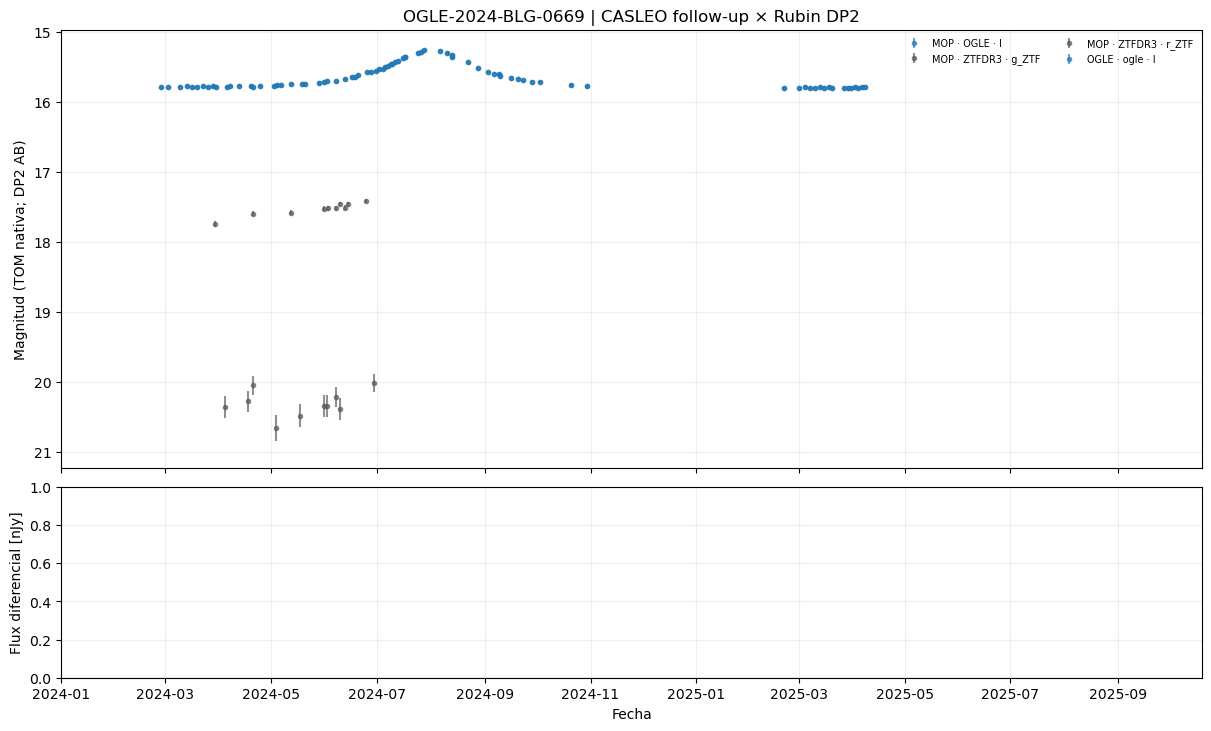

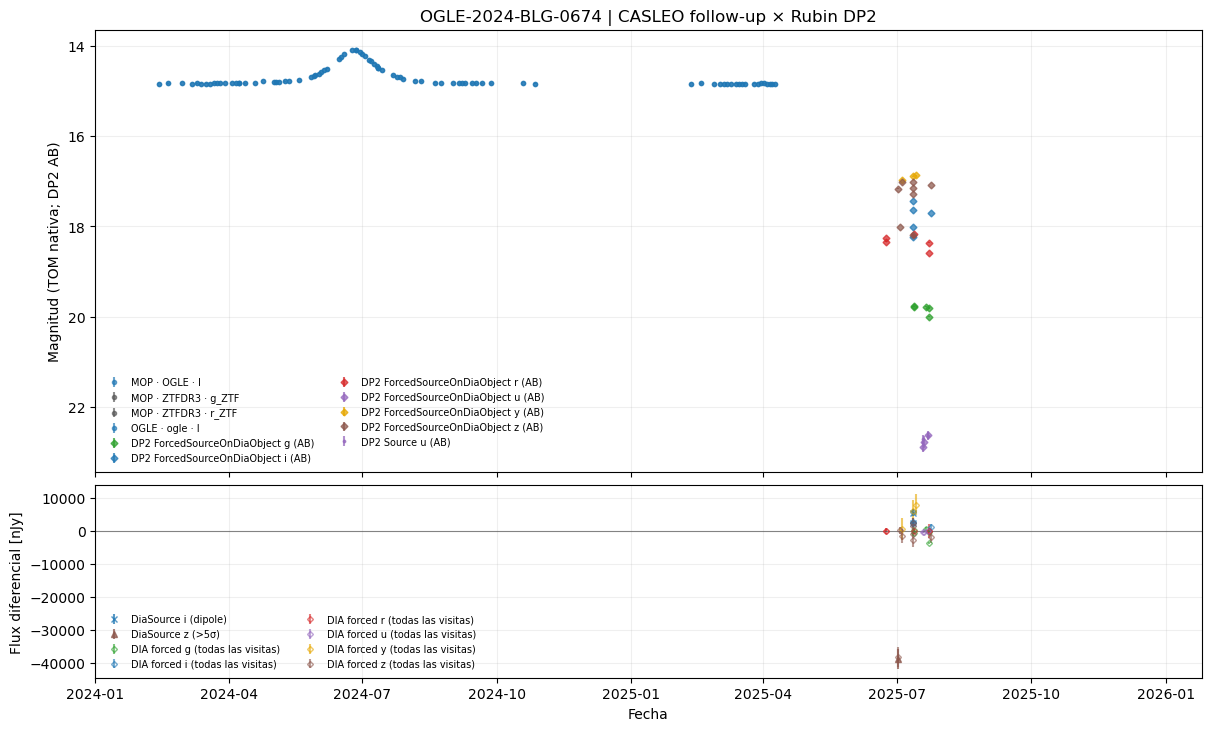

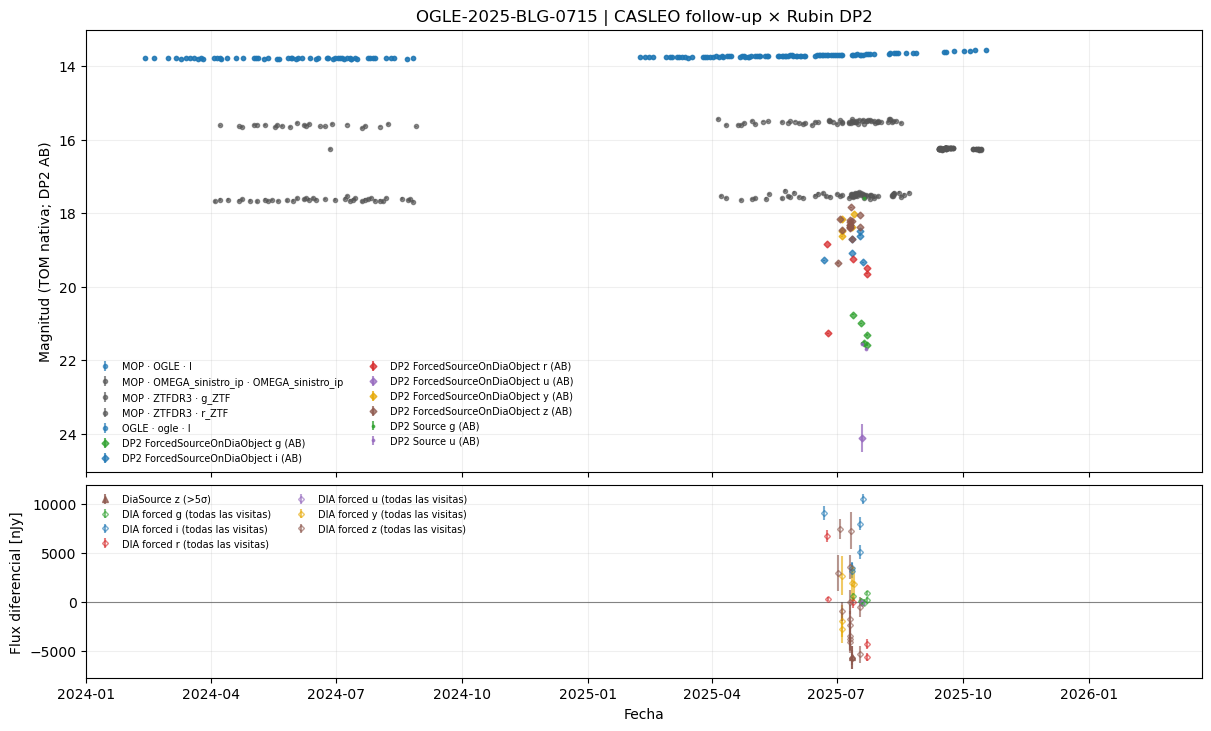

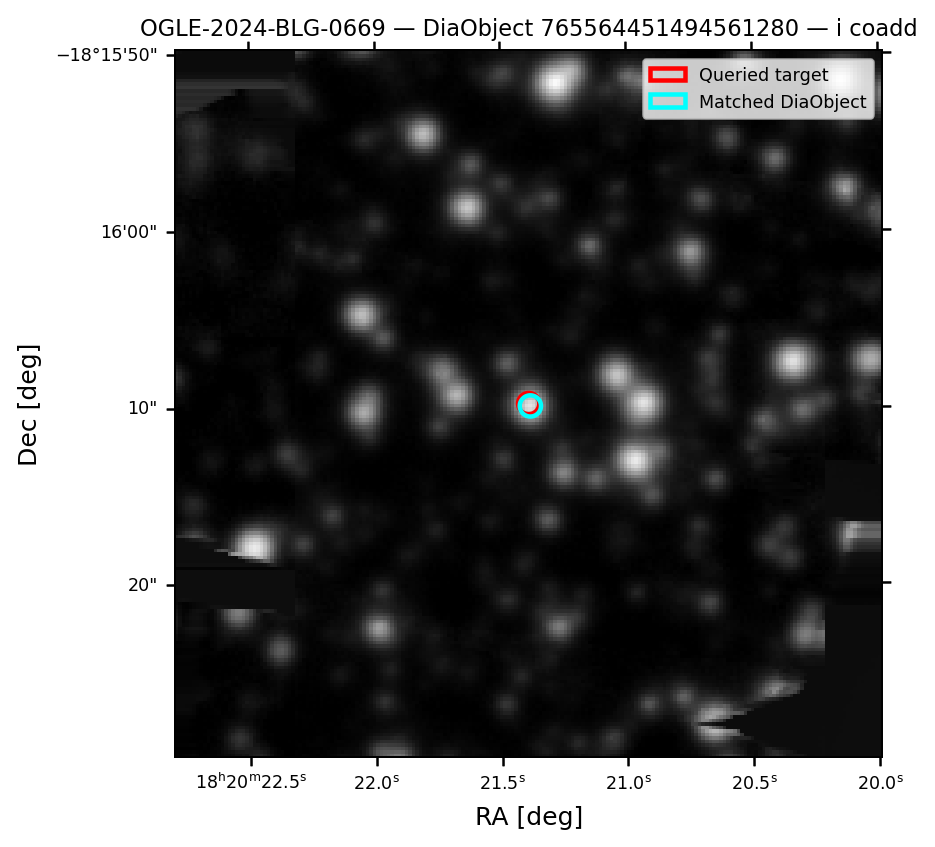

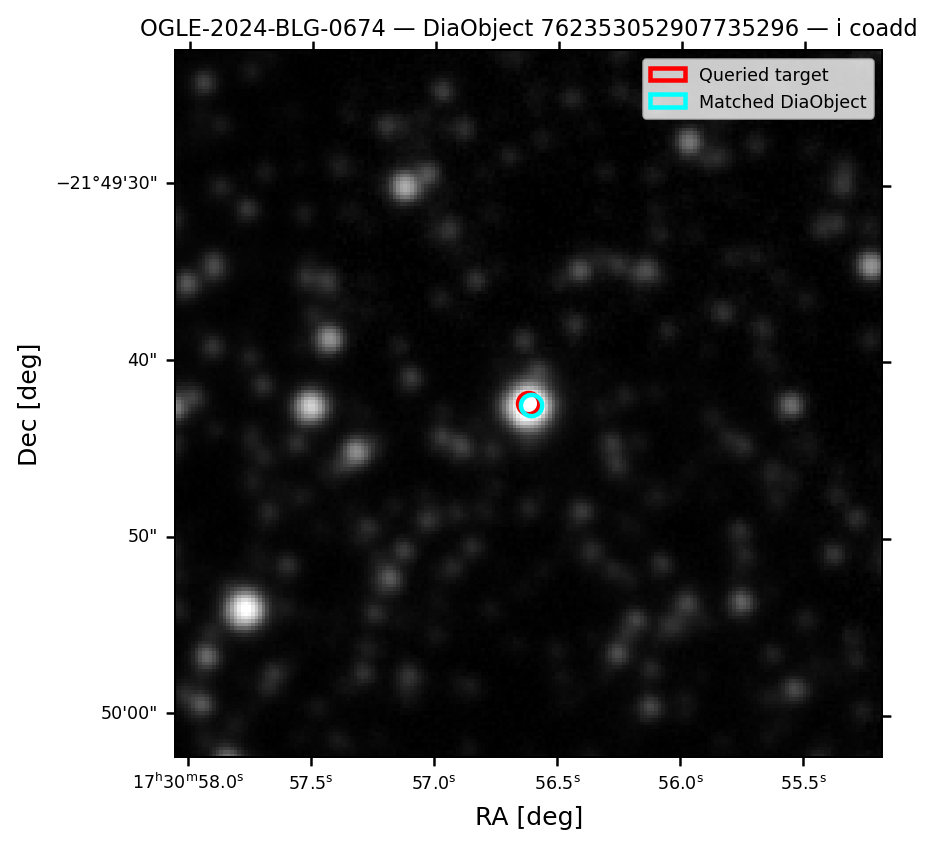

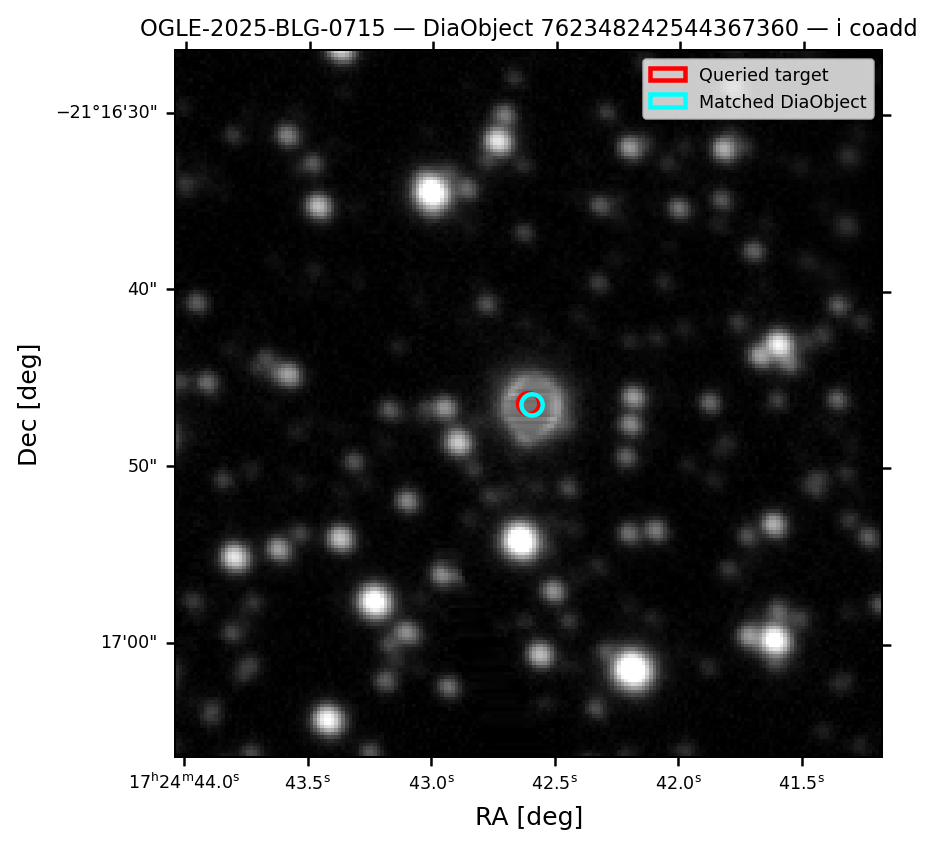

Figuras y tabla catalogada: /home/karennowo/target_selection/outputs/runs/casleo_lsst_presentation
Curvas guardadas: 6
Cutouts guardados: 6


In [6]:
MJD_ORIGIN = pd.Timestamp("1858-11-17")
FILTER_COLORS = {"u":"#9467bd", "g":"#2ca02c", "r":"#d62728", "i":"#1f77b4", "z":"#8c564b", "y":"#e6a700"}
DIRECT_MARKERS = {"Source":".", "ForcedSource":"s", "ForcedSourceOnDiaObject":"D"}

def mjd_to_datetime(values):
    return pd.to_datetime(pd.to_numeric(values, errors="coerce"), unit="D", origin=MJD_ORIGIN, errors="coerce")

def plot_event(target):
    name = str(target.Target)
    fig, (ax_mag, ax_dia) = plt.subplots(
        2, 1, figsize=(12, 7.2), sharex=True, constrained_layout=True,
        gridspec_kw={"height_ratios": [2.3, 1]},
    )
    dates = []

    # Panel superior: fotometría TOM en magnitud nativa y catálogos DP2
    # de imagen directa convertidos a magnitud AB (sólo fluxes positivos).
    tom = tom_all.loc[tom_all.Target.astype(str).eq(name)].copy()
    tom["date"] = mjd_to_datetime(tom.mjd)
    for (provider, survey, band), points in tom.dropna(subset=["date", "magnitude"]).groupby(
        ["provider", "survey", "band"], dropna=False
    ):
        color = FILTER_COLORS.get(str(band).lower(), "#555555")
        ax_mag.errorbar(
            points.date, points.magnitude, yerr=points.magnitude_error,
            fmt="o", ms=3, alpha=.65, color=color,
            label=f"{provider} · {survey} · {band}",
        )
        dates.extend(points.date.tolist())

    data = dp2_photometry.loc[dp2_photometry.Target.astype(str).eq(name)].copy()
    data["date"] = mjd_to_datetime(data.expMidptMJD)
    direct_catalogs = {"Source", "ForcedSource", "ForcedSourceOnDiaObject"}
    direct = data.loc[data.catalog.isin(direct_catalogs)].dropna(subset=["date", "psfFlux"]).copy()
    direct["magnitude_ab"] = np.nan
    direct["magnitude_error_ab"] = np.nan
    positive = direct.psfFlux.gt(0)
    direct.loc[positive, "magnitude_ab"] = 31.4 - 2.5 * np.log10(direct.loc[positive, "psfFlux"])
    usable_error = positive & direct.psfFluxErr.ge(0)
    direct.loc[usable_error, "magnitude_error_ab"] = (
        2.5 / np.log(10) * direct.loc[usable_error, "psfFluxErr"] / direct.loc[usable_error, "psfFlux"]
    )
    for (catalog, band), points in direct.dropna(subset=["magnitude_ab"]).groupby(
        ["catalog", "band"], dropna=False
    ):
        color = FILTER_COLORS.get(str(band).lower(), "#333333")
        ax_mag.errorbar(
            points.date, points.magnitude_ab, yerr=points.magnitude_error_ab,
            fmt=DIRECT_MARKERS[catalog], ms=3.5, alpha=.72, color=color,
            label=f"DP2 {catalog} {band} (AB)",
        )
        dates.extend(points.date.tolist())

    ax_mag.invert_yaxis()
    ax_mag.set_ylabel("Magnitud (TOM nativa; DP2 AB)")
    ax_mag.set_title(f"{name} | CASLEO follow-up × Rubin {DATA_RELEASE}")
    ax_mag.grid(alpha=.2)
    ax_mag.legend(fontsize=7, ncol=2, frameon=False, loc="best")

    # Panel inferior: flujo diferencial DIA. No se transforma a magnitud porque
    # puede ser cero/negativo. DiaSource son detecciones >5 sigma; ForcedSourceOnDiaObject
    # aporta también las épocas sin detección.
    dia = data.loc[data.catalog.eq("DiaSource")].dropna(subset=["date", "psfFlux"]).copy()
    if not dia.empty:
        if "isDipole" not in dia:
            dia["isDipole"] = False
        dia["isDipole"] = dia["isDipole"].map(
            lambda value: str(value).strip().casefold() in {"true", "1", "yes"}
            if pd.notna(value) else False
        )
        for (band, is_dipole), points in dia.groupby(["band", "isDipole"], dropna=False):
            color = FILTER_COLORS.get(str(band).lower(), "#333333")
            ax_dia.errorbar(
                points.date, points.psfFlux, yerr=points.psfFluxErr,
                fmt="x" if bool(is_dipole) else "^", ms=4, alpha=.75, color=color,
                label=f"DiaSource {band}" + (" (dipole)" if bool(is_dipole) else " (>5σ)"),
            )
            dates.extend(points.date.tolist())

    dia_forced = data.loc[data.catalog.eq("ForcedSourceOnDiaObject")].dropna(
        subset=["date", "psfDiffFlux", "psfDiffFluxErr"]
    ).copy()
    dia_forced["snr"] = dia_forced.psfDiffFlux.abs() / dia_forced.psfDiffFluxErr.where(
        dia_forced.psfDiffFluxErr.gt(0)
    )
    dia_forced = dia_forced.loc[dia_forced.snr.ge(5)]
    for band, points in dia_forced.groupby("band", dropna=False):
        color = FILTER_COLORS.get(str(band).lower(), "#333333")
        ax_dia.errorbar(
            points.date, points.psfDiffFlux, yerr=points.psfDiffFluxErr,
            fmt="D", ms=3, alpha=.6, mfc="none", color=color,
            label=f"DIA forced {band} (|S/N| ≥ 5)",
        )
        dates.extend(points.date.tolist())

    ax_dia.axhline(0, color="#555555", lw=.8, alpha=.7)
    ax_dia.set_ylabel("Flux diferencial [nJy]")
    ax_dia.set_xlabel("Fecha")
    ax_dia.grid(alpha=.2)
    if ax_dia.has_data():
        ax_dia.legend(fontsize=7, ncol=2, frameon=False, loc="best")

    if dates:
        first = min(pd.Timestamp(d) for d in dates)
        ax_dia.set_xlim(max(first, pd.Timestamp("2024-01-01")), None)
    return fig

# Recuperar las curvas disponibles de MOP, BHTOM y OPM con la interfaz común
# de target_selection. Son datos TOM existentes; DP2 sólo se consulta en TAP.
from target_selection.data_source import data_source
from target_selection.planning import collect_photometry

tom_targets = selected.rename(columns={"Target": "target_id", "RA_deg": "ra_deg", "Dec_deg": "dec_deg"}).copy()
try:
    opm_listing = data_source.get("opm").ranking()
    tom_targets = tom_targets.merge(
        opm_listing[["target_id", "opm_target_page_id"]].drop_duplicates("target_id"),
        on="target_id", how="left",
    )
except Exception as exc:
    print(f"No se pudo consultar el índice público OPM: {exc}")

tom_download = collect_photometry(
    tom_targets, providers=("mop", "bhtom", "opm"),
    query_all_tom_providers=True, include_associated_surveys=True,
    cache_dir=CACHE_ROOT, output_dir=OUTPUT_DIR / "tom_photometry", verbose=True,
)
if not tom_download.empty:
    fetched = tom_download.rename(columns={"target_id": "Target"})
    tom_all = pd.concat([tom_all, normalize_tom(fetched)], ignore_index=True)
    tom_all = tom_all.drop_duplicates(
        ["Target", "mjd", "band", "magnitude", "provider", "survey"], keep="last",
    )
print("Fotometría TOM disponible por proveedor:")
display(tom_all.loc[tom_all.Target.astype(str).isin(selected.Target.astype(str))]
        .groupby(["provider", "survey", "band"], dropna=False).size().rename("points").reset_index())

for target in selected.itertuples(index=False):
    fig = plot_event(target)
    fig.savefig(OUTPUT_DIR / f"{target.Target}_combined_lightcurve.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Cutout marcado, sólo para targets con DiaObject coincidente.
for target in selected.itertuples(index=False):
    if pd.isna(target.diaObjectId):
        continue
    dia = nearest_catalog_match("dp2.DiaObject", "ra", "dec", target.RA_deg, target.Dec_deg, MATCH_RADIUS_ARCSEC)
    saved = save_dia_match_cutout(
        butler=butler, data_release=release, target_name=str(target.Target),
        target_ra_deg=float(target.RA_deg), target_dec_deg=float(target.Dec_deg),
        dia_object_id=int(target.diaObjectId), dia_ra_deg=float(dia.ra), dia_dec_deg=float(dia.dec),
        output_path=OUTPUT_DIR / "cutouts" / f"{target.Target}_DP2_coadd.png",
    )
    if saved:
        display(Image(filename=str(saved)))
print("Figuras y tabla catalogada:", OUTPUT_DIR.resolve())
print("Curvas guardadas:", len(list(OUTPUT_DIR.glob("*_combined_lightcurve.png"))))
print("Cutouts guardados:", len(list((OUTPUT_DIR / "cutouts").glob("*.png"))) if (OUTPUT_DIR / "cutouts").exists() else 0)
